In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder,
                                   LabelEncoder, TargetEncoder)

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Embedding, Flatten, Dense, Dropout


## Cargamos el dataset

* Descargamos el csv de nuestro directorio principal del proyecto , mostrando la primera versión de nuestro dataset "dfTaxis"
* Procedemos al tratamiento de los datos y su limpieza
    * Al observar los nulos, mostramos que las únicas columnas con nulos son "SR_FLAG" y "dispatching_base_num" , estas dos no van a ser columnas que sean relevantes frente a nuestro estudio ni en el entrenamiento de nuestro modelo. Por ello , no se intervemdrá en esas dos columnas

In [110]:
dfTaxis=pd.read_csv('sample.csv')
dfTaxis.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag
0,HV0005,B02510,02/12/2019 11:10:30 AM,02/12/2019 11:19:14 AM,80,112,NaN
1,HV0005,B02510,02/12/2019 11:35:27 AM,02/12/2019 11:54:29 AM,256,125,NaN
2,HV0003,B02867,02/12/2019 11:03:14 AM,02/12/2019 11:21:04 AM,210,155,1.0
3,HV0003,B02867,02/12/2019 11:12:12 AM,02/12/2019 11:24:40 AM,155,155,1.0
4,HV0003,B02867,02/12/2019 11:50:05 AM,02/12/2019 11:59:14 AM,155,91,NaN


In [111]:
dfTaxis.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   hvfhs_license_num     200000 non-null  str    
 1   dispatching_base_num  199997 non-null  str    
 2   pickup_datetime       200000 non-null  str    
 3   dropoff_datetime      200000 non-null  str    
 4   PULocationID          200000 non-null  int64  
 5   DOLocationID          200000 non-null  int64  
 6   SR_Flag               43576 non-null   float64
dtypes: float64(1), int64(2), str(4)
memory usage: 10.7 MB


In [112]:
dfTaxis.isnull().sum()

hvfhs_license_num            0
dispatching_base_num         3
pickup_datetime              0
dropoff_datetime             0
PULocationID                 0
DOLocationID                 0
SR_Flag                 156424
dtype: int64

In [113]:
dfTaxis.shape

(200000, 7)

* Para limpiar y preparar los datos creamos de antemano una columna nueva que se llame "duración"
    1. Primero convertirmos los valores de pickup y dropoff a valores datetime
    2. Calculamos la distancia entre estos (duración del viaje) convirtiendo esta en minutos

In [114]:
dfTaxis['pickup_datetime'] = pd.to_datetime(dfTaxis['pickup_datetime'])
dfTaxis['dropoff_datetime'] = pd.to_datetime(dfTaxis['dropoff_datetime'])

dfTaxis['duracion'] = (dfTaxis['dropoff_datetime'] - dfTaxis['pickup_datetime']).dt.total_seconds() / 60

* Al mostrar las estadísticas numéricas de la nueva columna , encontramos que existen viajes con duración de 0 minutos y 0 segundos con fechas de recogida y destino eran iguales
    * Intuímos que estos han sido cancelados y se eliminan de nuestro dataset

In [115]:
dfTaxis['duracion'].describe()

count    200000.000000
mean         18.842232
std          13.039334
min           0.000000
25%           9.600000
50%          15.533333
75%          24.550000
max         371.466667
Name: duracion, dtype: float64

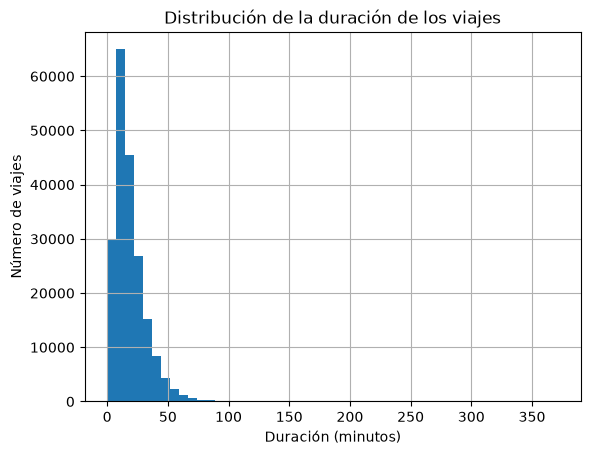

In [116]:
dfTaxis['duracion'].hist(bins=50)
plt.xlabel('Duración (minutos)')
plt.ylabel('Número de viajes')
plt.title('Distribución de la duración de los viajes')
plt.show()

In [117]:
# Viajes con duración igual o inferior a cero
dfTaxis[dfTaxis['duracion'] <= 0]

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
183512,HV0005,B02510,2019-03-21 22:00:40,2019-03-21 22:00:40,217,217,NaN,0.0


In [118]:
taxisClean = dfTaxis[dfTaxis['duracion'] > 0]

## Histogramas y aunar categorías

* Al mostrar los histogramas de nuestras futuras categorías observamso qeu existen varios datos donde se muestran una cantidad de datos menores , es decir , tienen pocos viajes o son zonas poco frecuentes
* Para confirmar esto , mostramos las estadísticas de cuantas veecs aparece una zona , la cual confirma que existen zonas que aparecen solo 1 vez

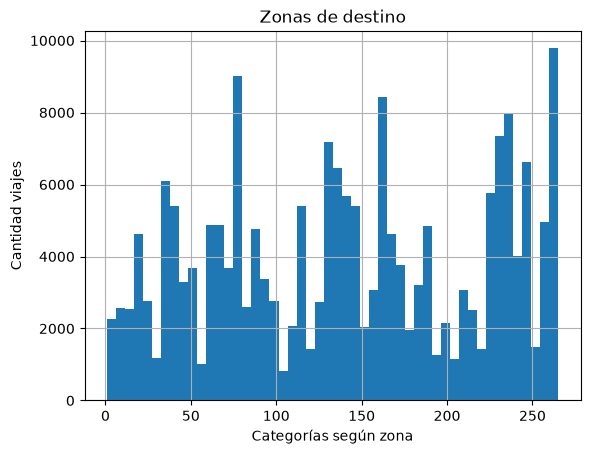

In [119]:
taxisClean['DOLocationID'].hist(bins=50)
#categoruias - localizaciones que tengan pocos viajes = localizaciones poco frecuentes
plt.title('Zonas de destino')
plt.xlabel('Categorías según zona')
plt.ylabel('Cantidad viajes')
plt.show()

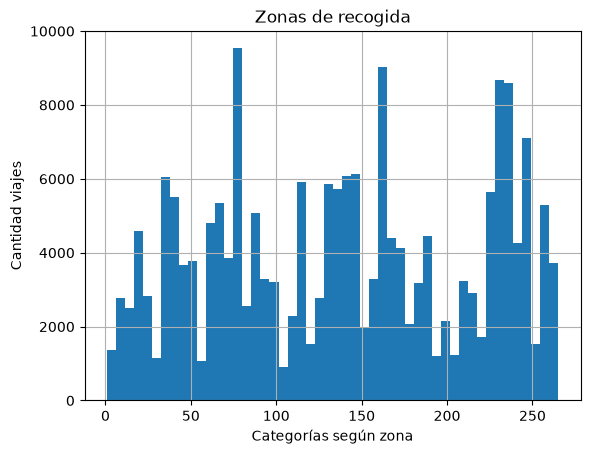

In [120]:
taxisClean['PULocationID'].hist(bins=50)
#categoruias - localizaciones que tengan pocos viajes = localizaciones poco frecuentes
plt.title('Zonas de recogida')
plt.xlabel('Categorías según zona')
plt.ylabel('Cantidad viajes')
plt.show()

In [121]:
taxisClean['PULocationID'].value_counts().describe()

count     260.000000
mean      769.226923
std       698.573499
min         1.000000
25%       214.250000
50%       527.500000
75%      1157.250000
max      3439.000000
Name: count, dtype: float64

In [122]:
taxisClean['DOLocationID'].value_counts().describe()

count     260.000000
mean      769.226923
std       771.788645
min         1.000000
25%       226.750000
50%       522.500000
75%      1136.750000
max      6282.000000
Name: count, dtype: float64

* Para poder decidir el umbral mínimo para aunar nuestras categorías vamos realizando los siguientes pasos :
    * Mostramos el avanze de la cantidad de categorías agrupadas que resultan al aunar las que tengan menos de 70 viajes 
    * Luego de 100 y de 200
* Tenemos que tener en consideración que tenemos 260 categorías en cada una de las columnas-> count  260.000000 , por lo que no podemos elegir un umbral demasiado alto ya que estaríamos agrupando muchas categorías y perdiendo demasiada información.

In [124]:
# Zonas que aparecen menos de 100 veces
print("Recogidas:")
print((taxisClean['PULocationID'].value_counts() < 100).sum())

print("Destinos:")
print((taxisClean['DOLocationID'].value_counts() <100).sum())

Recogidas:
37
Destinos:
34


In [131]:
# # Zonas que aparecen menos de 200 veces
# taxis200Recogida=(taxisClean['PULocationID'].value_counts() < 200).sum()
# taxis200Destino=(taxisClean['DOLocationID'].value_counts() < 200).sum()
# porcentajeEnViajesRecogida= taxis200Recogida / len(taxisClean) * 100
# porcentajeEnViajesDestino= taxis200Destino / len(taxisClean) * 100

# print(f"Recogidas: {taxis200Recogida} , Porcentaje de viajes frente al total : {porcentajeEnViajesRecogida}")
# print(f"Destinos: {taxis200Destino}, Porcentaje de viajes frente al total : {porcentajeEnViajesDestino}")

# print((taxisClean['PULocationID'].value_counts() < 200).sum())
# print(())
# print("Destinos:")
# print((taxisClean['DOLocationID'].value_counts() < 200).sum())

countRecogida = taxisClean['PULocationID'].value_counts()
countDestino = taxisClean['DOLocationID'].value_counts()

taxis200Recogida = (taxisClean['PULocationID'].value_counts() < 200).sum()
taxis200Destino = (taxisClean['PULocationID'].value_counts() < 200).sum()

viajesRecogida = countRecogida[countRecogida < 200].sum()
viajesDestino = countDestino[countDestino < 200].sum()

porcentajeEnViajesRecogida = viajesRecogida / len(taxisClean) * 100
porcentajeEnViajesDestino = viajesDestino / len(taxisClean) * 100

print(f"Recogidas: {taxis200Recogida} categorías, {viajesRecogida} viajes ({porcentajeEnViajesRecogida:.2f} %)")
print(f"Destinos: {taxis200Destino} categorías, {viajesDestino} viajes ({porcentajeEnViajesDestino:.2f} %)")

Recogidas: 63 categorías, 5521 viajes (2.76 %)
Destinos: 63 categorías, 5196 viajes (2.60 %)


* Por ello no vamos a elegir un umbral que se acerque mucho al primer cuartil de 25% del número total de categorías , ya que podría provocar que agrupásemos un número elevado de categorías, y que representa una cantidad de viajes considerable pero no demasiado alta .
* Para confirmar esto necesitamos estudiar un umbral que represente un número de categorías considerable y una cantidad de viajes no demasidado alta frente al total ,ya que nos estamso refiriendo a categorías que aparecen poco.


In [133]:
# Obtener la frecuencia de cada zona
frecuencias = taxisClean['PULocationID'].value_counts()

# Identificar las zonas con menos de 100 viajes
zonas_poco_frecuentes = frecuencias[frecuencias < 200].index

# Agruparlas en la categoría 0
taxisClean.loc[taxisClean['PULocationID'].isin(zonas_poco_frecuentes),'PULocationID'] = 0

In [134]:
# Obtener la frecuencia de cada zona
frecuencias = taxisClean['DOLocationID'].value_counts()

# Identificar las zonas con menos de 200 viajes
zonas_poco_frecuentes = frecuencias[frecuencias < 200].index

# Agruparlas en la categoría 0
taxisClean.loc[taxisClean['DOLocationID'].isin(zonas_poco_frecuentes),'DOLocationID'] = 0

In [135]:
print("Categorías de recogida:", taxisClean['PULocationID'].nunique())
print("Categorías de destino:", taxisClean['DOLocationID'].nunique())

print("\nFrecuencia de la categoría genérica:")
print("Recogidas:", (taxisClean['PULocationID'] == 0).sum())
print("Destinos:", (taxisClean['DOLocationID'] == 0).sum())

Categorías de recogida: 198
Categorías de destino: 201

Frecuencia de la categoría genérica:
Recogidas: 5521
Destinos: 5196


## Codificación por embeddings

* Para la codificación por embeddings para dos columnas categóricas realizaemos dos capas de embeddings separadas para poder estudiar la relación del destino con la duración del viaje y de la zona de recogida con la duración del viaje individualmente.
    1. Para trabajar con las categorías en embeddings tendremos que utilizar labelencoder con fittransform
    2. Con estos dos métodos permitimos que primero aprenda las categorías existentes para luego tranformarlas en valores de 0 a 1

* Notas:
    * Si tenemos 260 categorías de recogida, la capa podrá disponer de 260 vectores, uno para cada índice entre 0 y 260
    * Transforma cada categoría en un número entero consecutivo, desde 0 hasta el máximo índice.


In [138]:
LabelEncRecogida=LabelEncoder()
taxisClean['PULocationID']=LabelEncRecogida.fit_transform(taxisClean['PULocationID'])
taxisClean.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
0,HV0005,B02510,2019-02-12 11:10:30,2019-02-12 11:19:14,56,78,NaN,8.733333
1,HV0005,B02510,2019-02-12 11:35:27,2019-02-12 11:54:29,190,85,NaN,19.033333
2,HV0003,B02867,2019-02-12 11:03:14,2019-02-12 11:21:04,151,112,1.0,17.833333
3,HV0003,B02867,2019-02-12 11:12:12,2019-02-12 11:24:40,110,112,1.0,12.466667
4,HV0003,B02867,2019-02-12 11:50:05,2019-02-12 11:59:14,110,68,NaN,9.150000


In [139]:
LabelEncDestino=LabelEncoder()
taxisClean['DOLocationID']=LabelEncDestino.fit_transform(taxisClean['DOLocationID'])
taxisClean.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
0,HV0005,B02510,2019-02-12 11:10:30,2019-02-12 11:19:14,56,78,NaN,8.733333
1,HV0005,B02510,2019-02-12 11:35:27,2019-02-12 11:54:29,190,85,NaN,19.033333
2,HV0003,B02867,2019-02-12 11:03:14,2019-02-12 11:21:04,151,112,1.0,17.833333
3,HV0003,B02867,2019-02-12 11:12:12,2019-02-12 11:24:40,110,112,1.0,12.466667
4,HV0003,B02867,2019-02-12 11:50:05,2019-02-12 11:59:14,110,68,NaN,9.150000


In [140]:
nCategoriasPickup = taxisClean['PULocationID'].nunique()
nCategoriasDropoff = taxisClean['DOLocationID'].nunique()

print("Categorías de recogida:", nCategoriasPickup)
print("Categorías de destino:", nCategoriasDropoff)

Categorías de recogida: 198
Categorías de destino: 201


In [141]:
XPU=taxisClean['PULocationID']
XDO=taxisClean['DOLocationID']
yduracion=taxisClean['duracion'] #target

In [142]:
nCategoriasRecogida=taxisClean[['PULocationID']].value_counts().shape[0]
nCategoriasDestino=taxisClean[['DOLocationID']].value_counts().shape[0]


* Realizamos la capa de embeddings de cada una de las colummas a estudiar
    * Para este paso ajustamos los parámetros en función de nuestro dataset , es decir , calculamos el output con la raiz cuarta y el número de categorías adecuado

In [143]:
#PuLocation
modelRecogida = Sequential()
outputRecogida = int(1.6 * nCategoriasRecogida**0.25)

modelRecogida.add(Embedding(input_dim=nCategoriasRecogida, output_dim=outputRecogida, input_length=1, name="recogida_embedding"))

modelRecogida.add(Flatten())

modelRecogida.add(Dense(32, activation='relu'))
modelRecogida.add(Dropout(0.3))
modelRecogida.add(Dense(1, activation='relu'))

modelRecogida.compile(optimizer='adam',loss='mean_absolute_error', metrics=['mae'])
modelRecogida.summary()
# El modelo intentará predecir el 1 o 0. Para hacerlo, ajustará los pesos del Embedding.

modelRecogida.fit(XPU, yduracion, verbose=1,batch_size=32,
    epochs=4)


/home/pabilion/proyecto-taxis/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ recogida_embedding (Embedding)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 21s 2ms/step - loss: 9.5524 - mae: 9.5524
Epoch 2/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 9.1336 - mae: 9.1336
Epoch 3/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 9.0985 - mae: 9.0985
Epoch 4/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 9.0581 - mae: 9.0581


* Vamos a realizar una reduccion de dimensionalidad para representar los embeddings anteriores en 2 dimensiones, partiendo de los embeddings de la red neuronal


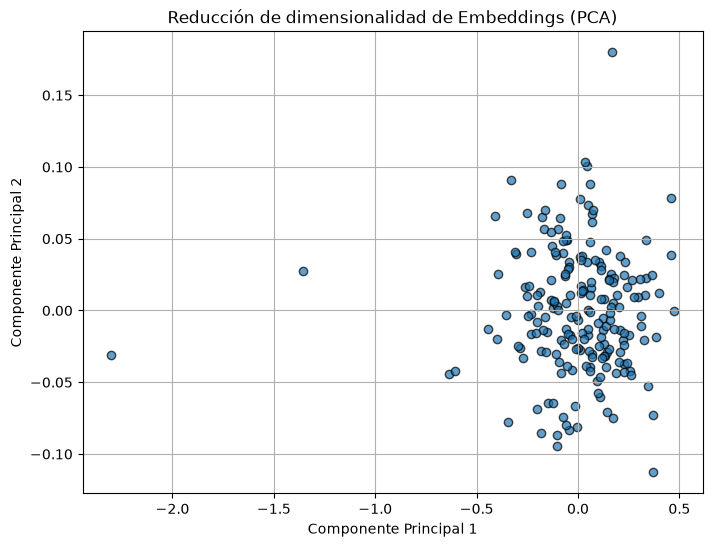

In [162]:

from sklearn.decomposition import PCA

embsRecogida= modelRecogida.get_layer('recogida_embedding').get_weights()[0]

pca_embeddings_recogida = PCA(n_components=2).fit_transform(embsRecogida)


plt.figure(figsize=(8, 6))
plt.scatter(pca_embeddings_recogida[:, 0], pca_embeddings_recogida[:, 1], alpha=0.7, edgecolors='k')

plt.title('Reducción de dimensionalidad de Embeddings (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

## Estudiar categoría de Recogida

* Al mostrar el PCA observamos que tenemos dos puntos muy alejados del centro, asi que procedemos a estudiar una
    * Como los embeddings resultantes están guardados en la variable  'pca_embeddings_recogida' que es un array ,podremos sacar de esa lista estos puntos .
    * Procedemos a filtrar por el valor x de nuestra gráfica , econtrándonos que existen dos puntos como en nuestro gráfico
    * Con el método .classes_ podemos acceder a las categorías originales no codificadas de 0 a 1, esto para poder revisar los datos originales y mirar sus estadísticas
* Procedemos a estudiar la zona 89

In [163]:
indices = np.where(pca_embeddings_recogida[:, 0] < -1.0)[0]
indicesOriginales= LabelEncRecogida.classes_[indices]
indicesOriginales

array([89, 95])

* En su estudio detectamos varias peculiaridades :
    * La media de duración de los viajes en esta categoría es mucho mayor que a la de las demás categorías en general 
    * Ya que en este caso la media de duración son 41.72 minutos y la media en general son 18.84
* Esto se confirma al mostrar una gráfica donde representamos la duración de los viajes , en la zona estudiada se muestra que hay una expansión hacia la derecha , mostrando que los viajes durán mas que la media.

In [148]:
indicesOriginales132=indicesOriginales[0]
datos_zona132 = taxisClean[taxisClean['PULocationID'] == indices[0]]
mediaTiempo=datos_zona132['duracion'].mean()
maxTiempo=datos_zona132['duracion'].max()
print("Zona original:", indicesOriginales132)
print(f"media : {mediaTiempo}, máxima : {maxTiempo}")
datos_zona132['duracion'].describe()

Zona original: 89
media : 41.726085547634476, máxima : 164.85


count    3086.000000
mean       41.726086
std        19.755993
min         0.066667
25%        29.320833
50%        39.983333
75%        52.504167
max       164.850000
Name: duracion, dtype: float64

In [ ]:
print("Media general:", taxisClean['duracion'].mean())
print("Media zona 132:", datos_zona132['duracion'].mean())

Media general: 18.842325878296055
Media zona 132: 41.726085547634476


<Axes: >

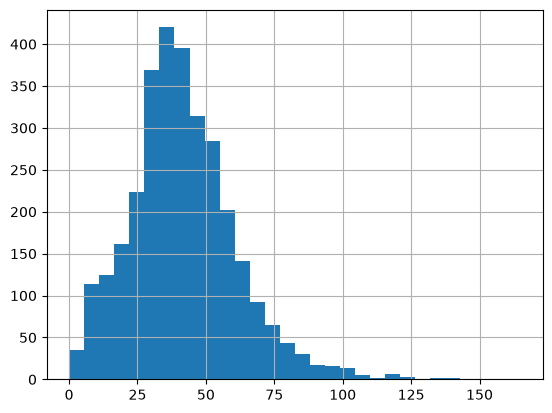

In [151]:
datos_zona132['duracion'].hist(bins=30)

<Axes: >

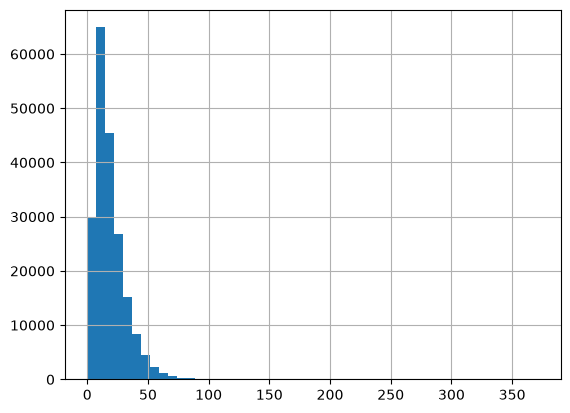

In [152]:
taxisClean['duracion'].hist(bins=50)

In [153]:
#DOLocation
model = Sequential()
output = int(1.6 * nCategoriasDestino**0.25)

model.add(Embedding(input_dim=nCategoriasDestino, output_dim=output, input_length=1, name="destino_embedding"))

model.add(Flatten())

model.add(Dense(32, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='relu'))

model.compile(optimizer='adam',loss='mean_absolute_error', metrics=['mae'])
model.summary()
# El modelo intentará predecir el 1 o 0. Para hacerlo, ajustará los pesos del Embedding.

model.fit(XDO, yduracion, verbose=1,batch_size=32,
    epochs=4)

/home/pabilion/proyecto-taxis/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ destino_embedding (Embedding)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step - loss: 9.1855 - mae: 9.1855
Epoch 2/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 8.8260 - mae: 8.8260
Epoch 3/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 8.7954 - mae: 8.7954
Epoch 4/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 8.7867 - mae: 8.7867


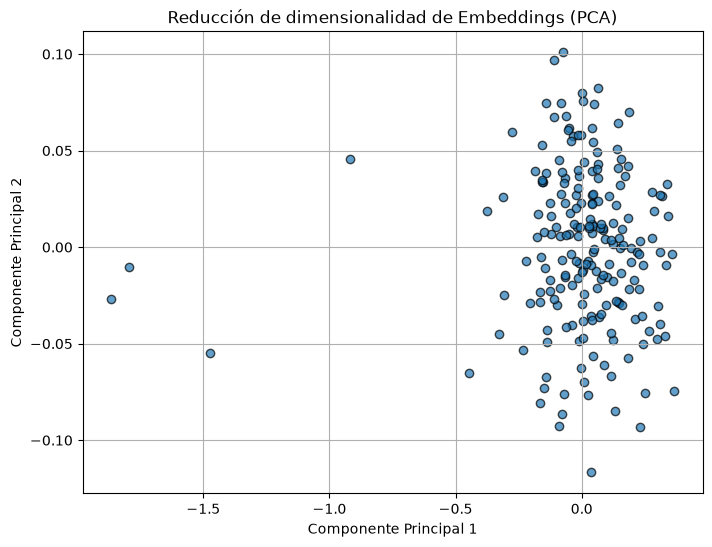

In [164]:
from sklearn.decomposition import PCA

embsdestino= model.get_layer('destino_embedding').get_weights()[0]

pca_embeddings = PCA(n_components=2).fit_transform(embsdestino)


plt.figure(figsize=(8, 6))
plt.scatter(pca_embeddings[:, 0], pca_embeddings[:, 1], alpha=0.7, edgecolors='k')

plt.title('Reducción de dimensionalidad de Embeddings (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

## Estudiar categoría de destino
* Procedemos a estudiar la categoría 1

In [ ]:
indicesdestino = np.where(pca_embeddings[:, 0] < -1.0)[0]
indicesOriginalesdestino= LabelEncDestino.classes_[indicesdestino]
indicesOriginalesdestino

array([  1,  91, 200])

In [224]:
# indicesdestinoNormales = np.where(pca_embeddings[:, 0] > 0.0)[0]
indicesdestinoNormales = np.where((pca_embeddings[:, 0] > 0.0) &(pca_embeddings[:, 1] > 0.0))[0]
datos_zonaCentral = taxisClean[taxisClean['DOLocationID'] == indicesdestinoNormales[0]]
datos_zonaCentral

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
313,HV0005,B02510,2019-02-12 11:38:10,2019-02-12 12:02:33,192,5,NaN,24.383333
364,HV0003,B02887,2019-02-12 11:19:07,2019-02-12 11:33:37,131,5,NaN,14.500000
1622,HV0003,B02888,2019-02-12 11:17:36,2019-02-12 11:26:50,156,5,1.0,9.233333
1643,HV0005,B02510,2019-02-12 11:19:20,2019-02-12 11:29:38,0,5,NaN,10.300000
3008,HV0003,B02887,2019-02-12 11:15:44,2019-02-12 11:21:33,156,5,NaN,5.816667
...,...,...,...,...,...,...,...,...
198717,HV0003,B02876,2019-03-23 01:34:58,2019-03-23 01:59:20,84,5,NaN,24.366667
198949,HV0003,B02875,2019-03-23 01:26:12,2019-03-23 01:40:07,146,5,1.0,13.916667
198988,HV0003,B02875,2019-03-23 01:28:39,2019-03-23 01:42:52,143,5,NaN,14.216667
199422,HV0003,B02764,2019-03-23 01:00:20,2019-03-23 01:13:22,89,5,1.0,13.033333


In [218]:
datos_zona1 = taxisClean[taxisClean['DOLocationID'] == indicesdestino[2]]

datos_zona1['duracion'].describe()

count    6282.000000
mean       36.057336
std        21.728262
min         0.950000
25%        19.887500
50%        32.033333
75%        47.354167
max       270.383333
Name: duracion, dtype: float64

In [219]:
for indice in indicesdestinoNormales:
    print(
        "Índice:", indice,
        "Zona original:", LabelEncDestino.classes_[indice],
        "X:", pca_embeddings[indice, 0],
        "Y:", pca_embeddings[indice, 1]
    )

Índice: 5 Zona original: 5 X: 0.184487 Y: 0.015056653
Índice: 10 Zona original: 10 X: 0.14458843 Y: 0.06435533
Índice: 12 Zona original: 12 X: 0.108646035 Y: 0.02628843
Índice: 15 Zona original: 15 X: 0.040207744 Y: 0.027065434
Índice: 18 Zona original: 18 X: 0.28533313 Y: 0.018665545
Índice: 23 Zona original: 23 X: 0.03900954 Y: 0.061797287
Índice: 26 Zona original: 26 X: 0.12342936 Y: 0.0015079859
Índice: 27 Zona original: 27 X: 0.039923966 Y: 0.022708587
Índice: 29 Zona original: 29 X: 0.083403856 Y: 0.008850502
Índice: 36 Zona original: 36 X: 0.041169792 Y: 0.007103895
Índice: 40 Zona original: 40 X: 0.06467605 Y: 0.023846097
Índice: 42 Zona original: 42 X: 0.039931238 Y: 0.02217709
Índice: 44 Zona original: 44 X: 0.15330565 Y: 0.032285906
Índice: 51 Zona original: 51 X: 0.14659652 Y: 0.004622875
Índice: 52 Zona original: 52 X: 0.1639019 Y: 0.0011976305
Índice: 55 Zona original: 55 X: 0.16102439 Y: 0.009361847
Índice: 57 Zona original: 57 X: 0.1379368 Y: 0.050898906
Índice: 60 Zona

In [220]:
print("DESTINO EXTERIOR 1")
print(datos_zona1['duracion'].describe())

print("\nDESTINO CENTRAL")
print(datos_zonaCentral['duracion'].describe())

DESTINO EXTERIOR 1
count    6282.000000
mean       36.057336
std        21.728262
min         0.950000
25%        19.887500
50%        32.033333
75%        47.354167
max       270.383333
Name: duracion, dtype: float64

DESTINO CENTRAL
count    380.000000
mean      15.336491
std       10.986162
min        2.333333
25%        7.983333
50%       12.383333
75%       18.670833
max       80.816667
Name: duracion, dtype: float64


In [208]:
datos_zona91 = taxisClean[
    taxisClean['DOLocationID'] == LabelEncDestino.transform([91])[0]
]

print("Destino 1:", datos_zona1['PULocationID'].nunique())
print("Destino 91:", datos_zona91['PULocationID'].nunique())

Destino 1: 188
Destino 91: 195


In [ ]:
datosotrazonanormal=taxisClean[taxisClean['DOLocationID'] == indicesdestino[1]]
frecuenciasotra = datosotrazonanormal['PULocationID'].value_counts()

frecuenciasotra.hist(bins=15)

plt.title("Distribución de viajes por zona de recogida")
plt.xlabel("Número de viajes")
plt.ylabel("Número de zonas")
plt.show()

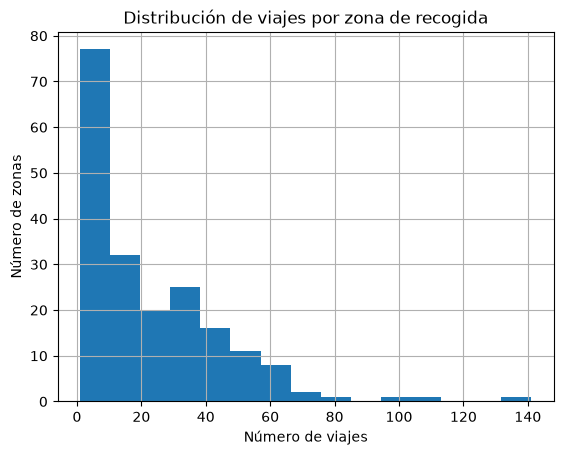

In [202]:
datosotrazonapeculiar=taxisClean[taxisClean['DOLocationID'] == indicesdestino[1]]
frecuenciasotra = datosotrazonapeculiar['PULocationID'].value_counts()

frecuenciasotra.hist(bins=15)

plt.title("Distribución de viajes por zona de recogida")
plt.xlabel("Número de viajes")
plt.ylabel("Número de zonas")
plt.show()

In [204]:
print("minimo general:", taxisClean['duracion'].min())
print("mínimo zona 1:", datos_zona1['duracion'].min())

minimo general: 0.016666666666666666
mínimo zona 1: 0.95


In [195]:
datos_zona1['PULocationID'].value_counts().head(10)

PULocationID
169    52
170    42
45     41
115    34
173    33
31     32
116    32
118    30
0      29
74     28
Name: count, dtype: int64

In [196]:
datos_zona1['PULocationID'].nunique()

116

In [199]:
frecuencias2 = datos_zona1['PULocationID'].value_counts()

porcentajeTop10 = frecuencias2.head(10).sum() / len(datos_zona1) * 100

print(f"Porcentaje de viajes desde las 10 recogidas más frecuentes: {porcentajeTop10:.2f}%")

Porcentaje de viajes desde las 10 recogidas más frecuentes: 32.56%


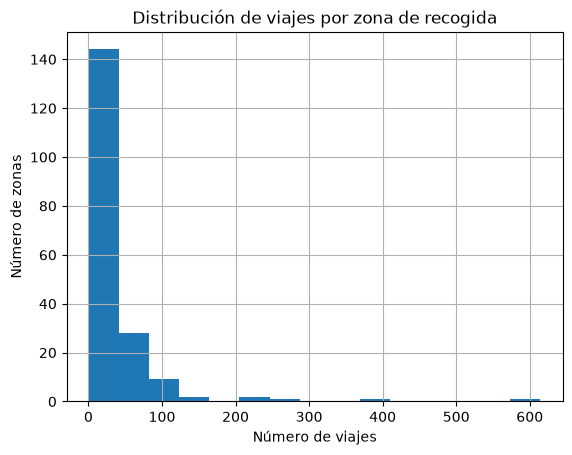

In [205]:
frecuencias3 = datos_zona1['PULocationID'].value_counts()

frecuencias3.hist(bins=15)

plt.title("Distribución de viajes por zona de recogida")
plt.xlabel("Número de viajes")
plt.ylabel("Número de zonas")
plt.show()

In [188]:
datos_zona1['duracion'].sort_values(ascending=False).head(10)

71728     136.566667
160035    109.166667
74302     101.033333
39183      96.533333
24555      88.483333
65383      88.183333
166032     88.033333
5143       84.033333
59332      83.983333
28121      83.900000
Name: duracion, dtype: float64

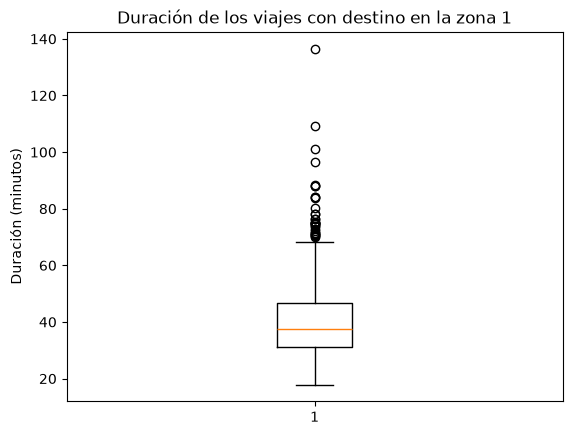

In [187]:
plt.boxplot(datos_zona1['duracion'])
plt.title("Duración de los viajes con destino en la zona 1")
plt.ylabel("Duración (minutos)")
plt.show()

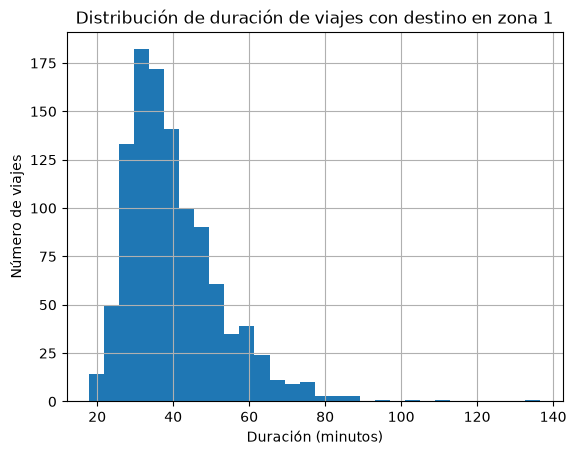

In [189]:
datos_zona1['duracion'].hist(bins=30)
plt.title("Distribución de duración de viajes con destino en zona 1")
plt.xlabel("Duración (minutos)")
plt.ylabel("Número de viajes")
plt.show()

In [206]:
print("Todos los trayectos:")
print((taxisClean['duracion'] > 30).mean() * 100)

print("Destino zona 1:")
print((datos_zona1['duracion'] > 30).mean() * 100)


Todos los trayectos:
16.072080360401802
Destino zona 1:
53.709009869468325


In [207]:
print("Todos los trayectos:")
print((taxisClean['duracion'] > 60).mean() * 100)

print("Destino zona 1:")
print((datos_zona1['duracion'] > 60).mean() * 100)

Todos los trayectos:
1.2400062000310001
Destino zona 1:
12.30499840815027


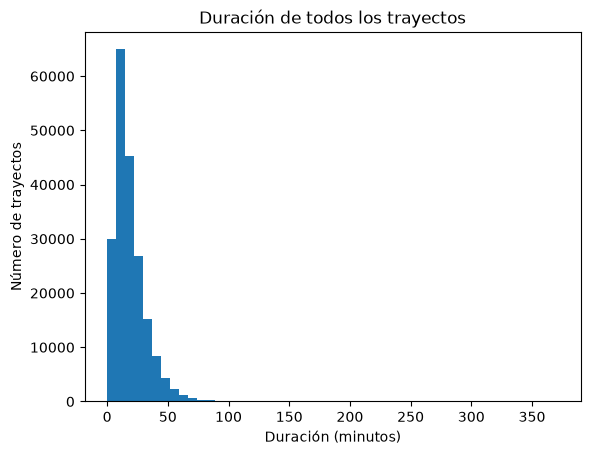

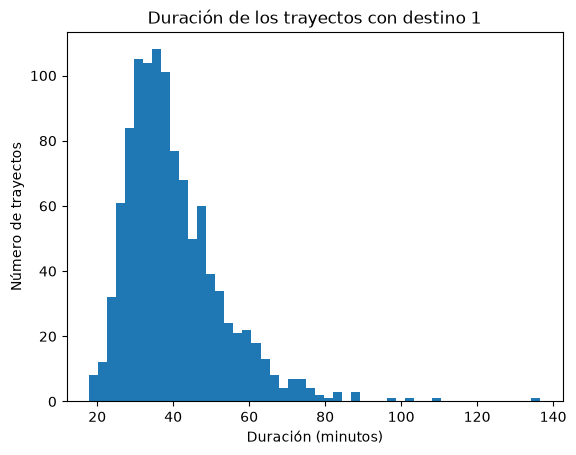

In [186]:
import matplotlib.pyplot as plt

plt.hist(taxisClean['duracion'], bins=50)
plt.title("Duración de todos los trayectos")
plt.xlabel("Duración (minutos)")
plt.ylabel("Número de trayectos")
plt.show()

plt.hist(datos_zona1['duracion'], bins=50)
plt.title("Duración de los trayectos con destino 1")
plt.xlabel("Duración (minutos)")
plt.ylabel("Número de trayectos")
plt.show()